# Scrap price model

Target: monthly EU scrap export price (EUR/t) from notebook 1.
Drivers: pig iron and DRI import prices, export volumes, Türkiye's share, and World Bank monthly prices (iron ore, coal, EU gas, Brent).

In [1]:
import numpy as np
import pandas as pd
from pandas import Series, DataFrame
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set()

import requests, io
import warnings
warnings.filterwarnings('ignore')

## Data

In [2]:
trade = pd.read_csv('../data/processed/fact_trade_monthly.csv', dtype={'product': str}, parse_dates=['date'])
ext = trade[trade['partner'] == 'EXT_EU']

def unit_price(product, flow):
    d = ext[(ext['product'] == product) & (ext['flow'] == flow)].groupby('date')[['eur', 'tonnes']].sum()
    return d['eur'] / d['tonnes']

exp = trade[(trade['product'] == '7204') & (trade['flow'] == 'export') & (trade['partner_group'].isin(['OECD', 'non-OECD']))]

df = DataFrame({
    'scrap_eur_t': unit_price('7204', 'export'),
    'pig_iron_eur_t': unit_price('7201', 'import'),
    'dri_eur_t': unit_price('720310', 'import'),
    'export_kt': exp.groupby('date')['tonnes'].sum() / 1e3,
    'turkey_share': exp[exp['partner'] == 'TR'].groupby('date')['tonnes'].sum() / exp.groupby('date')['tonnes'].sum()})
df.tail()

,scrap_eur_t,pig_iron_eur_t,dri_eur_t,export_kt,turkey_share
date,,,,,
2026-05-01,376.774056,393.028274,334.037033,1456.514827,0.680178
2026-06-01,380.631083,385.652641,323.509193,1355.689289,0.538332
2026-07-01,361.637470,441.427346,202.795075,1383.241575,0.661161
2026-08-01,350.536461,431.484820,334.738151,1212.516011,0.606599
2026-09-01,359.379882,449.433744,350.297011,1306.256957,0.614557


In [3]:
url = 'https://thedocs.worldbank.org/en/doc/74e8be41ceb20fa0da750cda2f6b9e4e-0050012026/related/CMO-Historical-Data-Monthly.xlsx'
res = requests.get(url).content
wb = pd.read_excel(io.BytesIO(res), sheet_name='Monthly Prices', header=4)

wb = wb.rename(columns={wb.columns[0]: 'period'}).iloc[2:]
wb['date'] = pd.to_datetime(wb['period'].str.replace('M', '-'))
wb = wb.set_index('date')[['Iron ore, cfr spot', 'Coal, Australian', 'Natural gas, Europe', 'Crude oil, Brent']]
wb.columns = ['iron_ore_usd', 'coal_usd', 'eu_gas_usd', 'brent_usd']
wb = wb.apply(pd.to_numeric, errors='coerce')

df = df.join(wb).dropna()
print('Shape:', df.shape, df.index.min().date(), '->', df.index.max().date())
df.describe()

Shape: (141, 9) 2015-01-01 -> 2026-09-01


,scrap_eur_t,pig_iron_eur_t,dri_eur_t,export_kt,turkey_share,iron_ore_usd,coal_usd,eu_gas_usd,brent_usd
count,141.000000,141.000000,141.000000,141.000000,141.000000,141.000000,141.000000,141.000000,141.000000
mean,318.683054,369.338449,257.912646,1520.954235,0.602377,97.716312,124.129787,11.745532,68.205674
std,69.699918,95.416083,72.252250,315.283372,0.079122,33.508120,81.364929,11.019702,19.442365
min,180.934485,184.184141,120.473815,620.544646,0.376921,40.500000,49.000000,1.580000,23.300000
25%,270.523531,312.930878,206.344872,1306.532961,0.547385,70.400000,69.700000,5.180000,54.900000
50%,305.010920,350.016939,238.471333,1562.576180,0.606599,97.300000,104.400000,8.150000,66.800000
75%,369.690863,406.694085,312.472885,1726.813470,0.661161,113.500000,138.600000,12.920000,80.500000
max,559.885800,664.997190,494.542240,2264.921206,0.790400,214.400000,430.800000,70.040000,120.400000


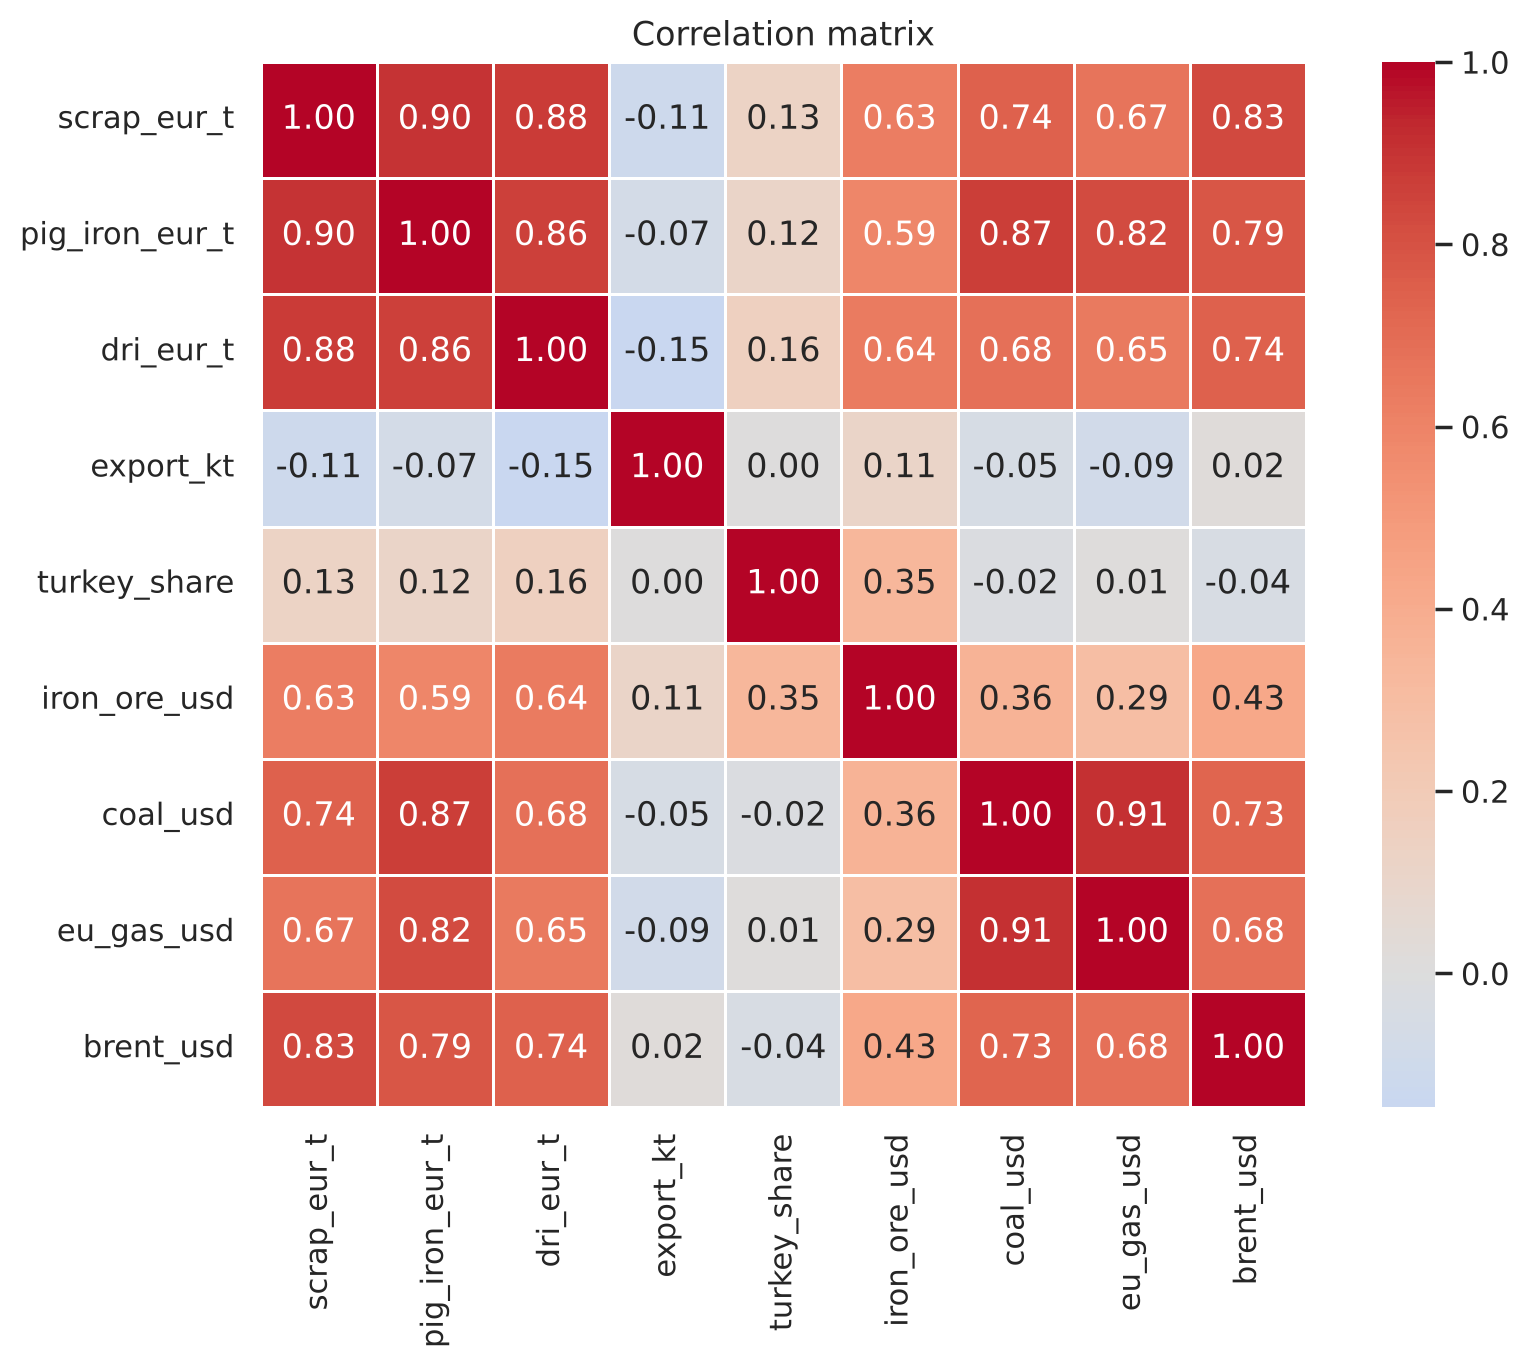

In [4]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', center=0, square=True, linewidths=0.5)
plt.title('Correlation matrix')
plt.tight_layout()
plt.savefig('../outputs/figures/08_price_correlations.png')
plt.show()

## Features
Drivers lagged by one month, log of prices. Train 2015-2023, test 2024-2026.

In [5]:
X = DataFrame(index=df.index)
for c in ['pig_iron_eur_t', 'dri_eur_t', 'iron_ore_usd', 'coal_usd', 'eu_gas_usd', 'brent_usd']:
    X['log_' + c] = np.log(df[c]).shift(1)
X['export_kt'] = df['export_kt'].shift(1)
X['turkey_share'] = df['turkey_share'].shift(1)
y = np.log(df['scrap_eur_t'])

X = X.dropna()
y = y.loc[X.index]

X_train, X_test = X[X.index < '2024-01-01'], X[X.index >= '2024-01-01']
y_train, y_test = y[y.index < '2024-01-01'], y[y.index >= '2024-01-01']
print(X_train.shape, X_test.shape)

(107, 8) (33, 8)


## Models

In [6]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    'LinearRegression': Pipeline([('scaler', StandardScaler()), ('model', LinearRegression())]),
    'Ridge': Pipeline([('scaler', StandardScaler()), ('model', Ridge(alpha=1.0))]),
    'DecisionTree': DecisionTreeRegressor(max_depth=4, random_state=0),
    'RandomForest': RandomForestRegressor(n_estimators=400, max_depth=6, random_state=0)}

actual = np.exp(y_test)
scores = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = np.exp(model.predict(X_test))
    scores[name] = [mean_absolute_error(actual, pred), mean_squared_error(actual, pred) ** 0.5, r2_score(actual, pred)]

naive = df['scrap_eur_t'].shift(1).loc[X_test.index]
scores['Naive (last month)'] = [mean_absolute_error(actual, naive), mean_squared_error(actual, naive) ** 0.5, r2_score(actual, naive)]

scores = DataFrame(scores, index=['MAE', 'RMSE', 'R2']).T.sort_values('MAE')
scores

,MAE,RMSE,R2
Naive (last month),10.749584,13.605577,0.752453
Ridge,23.352103,26.398571,0.068069
LinearRegression,24.714536,27.940283,-0.043962
RandomForest,30.575987,37.557617,-0.886337
DecisionTree,33.450093,42.086058,-1.368643


Level models are worse than just using last month's price. So next I predict the monthly change instead.

In [7]:
Xc = DataFrame(index=df.index)
for c in ['pig_iron_eur_t', 'dri_eur_t', 'iron_ore_usd', 'coal_usd', 'eu_gas_usd', 'brent_usd']:
    Xc['d_' + c] = np.log(df[c]).diff().shift(1)
Xc['d_scrap_last_month'] = np.log(df['scrap_eur_t']).diff().shift(1)
Xc['d_export_kt'] = np.log(df['export_kt']).diff().shift(1)
yc = np.log(df['scrap_eur_t']).diff()

Xc = Xc.dropna()
yc = yc.loc[Xc.index]
Xc_train, Xc_test = Xc[Xc.index < '2024-01-01'], Xc[Xc.index >= '2024-01-01']
yc_train, yc_test = yc[yc.index < '2024-01-01'], yc[yc.index >= '2024-01-01']

last_price = df['scrap_eur_t'].shift(1).loc[Xc_test.index]
actual_c = df['scrap_eur_t'].loc[Xc_test.index]

ridge_c = Pipeline([('scaler', StandardScaler()), ('model', Ridge(alpha=5.0))])
ridge_c.fit(Xc_train, yc_train)
pred_c = ridge_c.predict(Xc_test)

print('MAE naive (no change): {:.2f} EUR/t'.format(mean_absolute_error(actual_c, last_price)))
print('MAE ridge on changes:  {:.2f} EUR/t'.format(mean_absolute_error(actual_c, last_price * np.exp(pred_c))))
print('Direction correct:     {:.0%}'.format((np.sign(pred_c) == np.sign(yc_test)).mean()))

MAE naive (no change): 10.75 EUR/t
MAE ridge on changes:  9.88 EUR/t
Direction correct:     67%


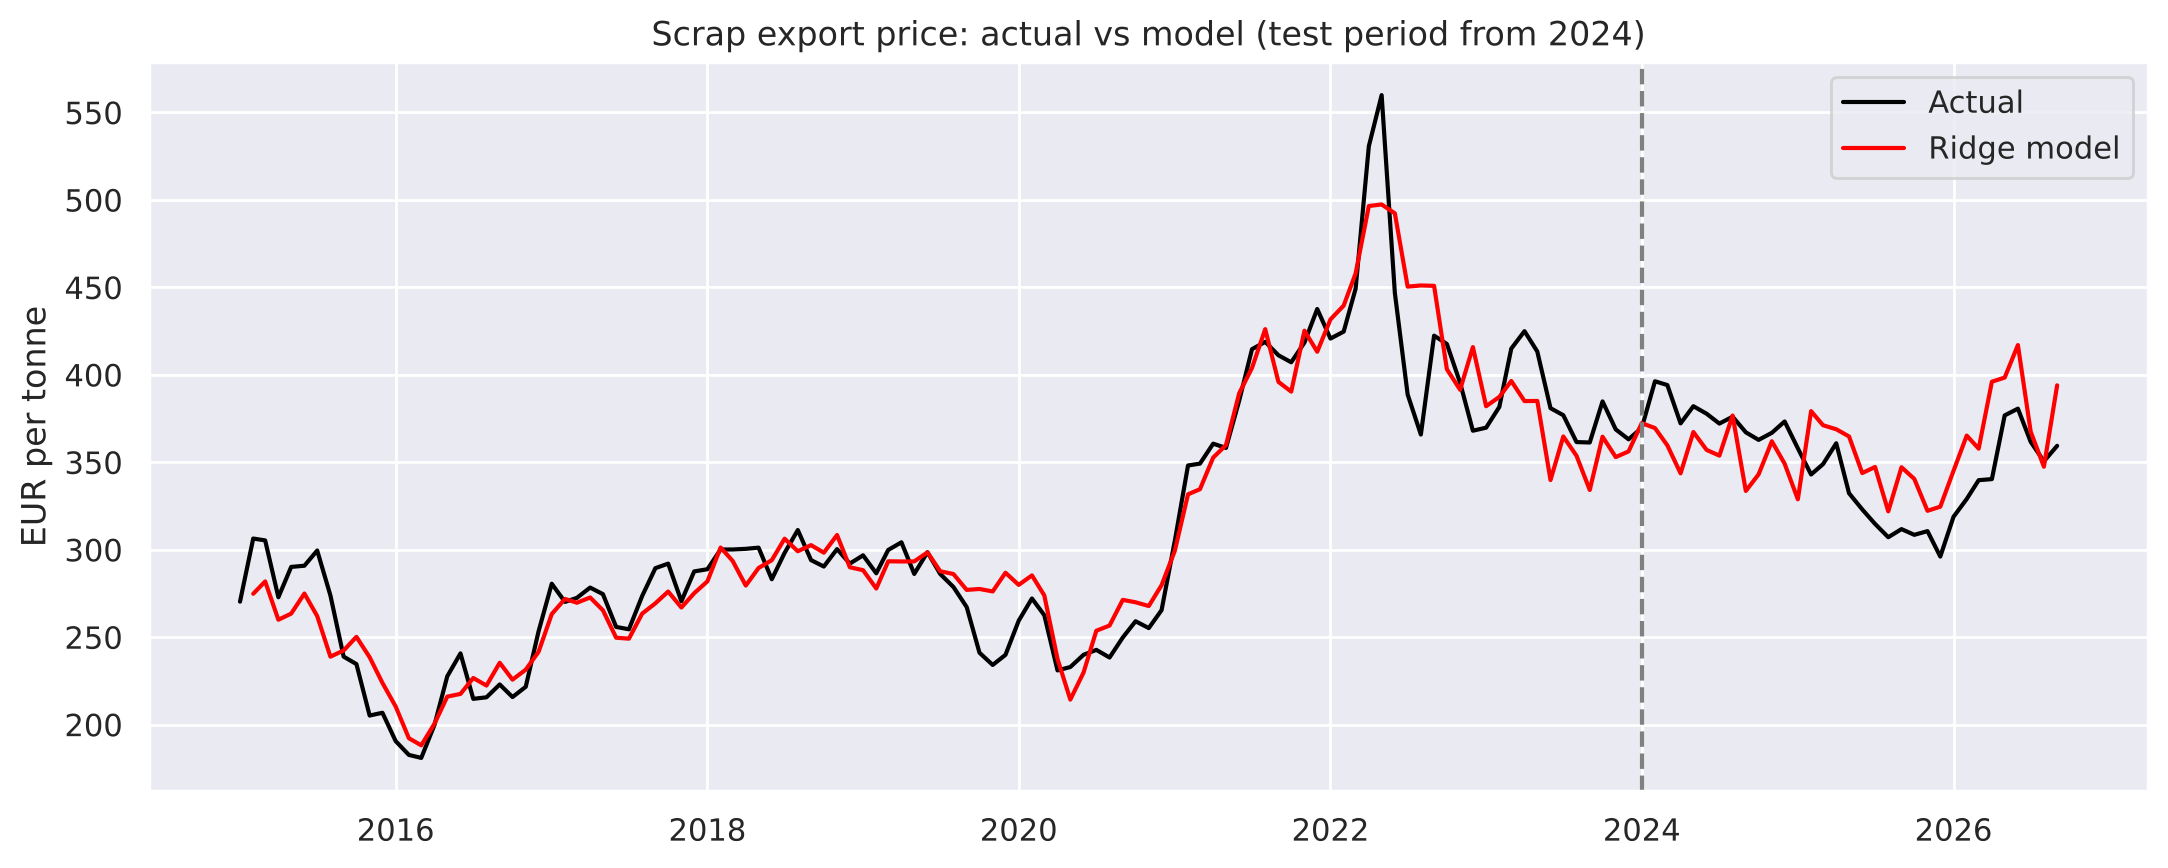

In [8]:
best = models['Ridge']
fit = Series(np.exp(best.predict(X)), index=X.index)

plt.figure(figsize=(11, 4.5))
plt.plot(df['scrap_eur_t'], color='black', label='Actual')
plt.plot(fit, color='red', label='Ridge model')
plt.axvline(pd.Timestamp('2024-01-01'), color='grey', linestyle='--')
plt.title('Scrap export price: actual vs model (test period from 2024)')
plt.ylabel('EUR per tonne')
plt.legend()
plt.tight_layout()
plt.savefig('../outputs/figures/09_price_model_fit.png')
plt.show()

## Drivers

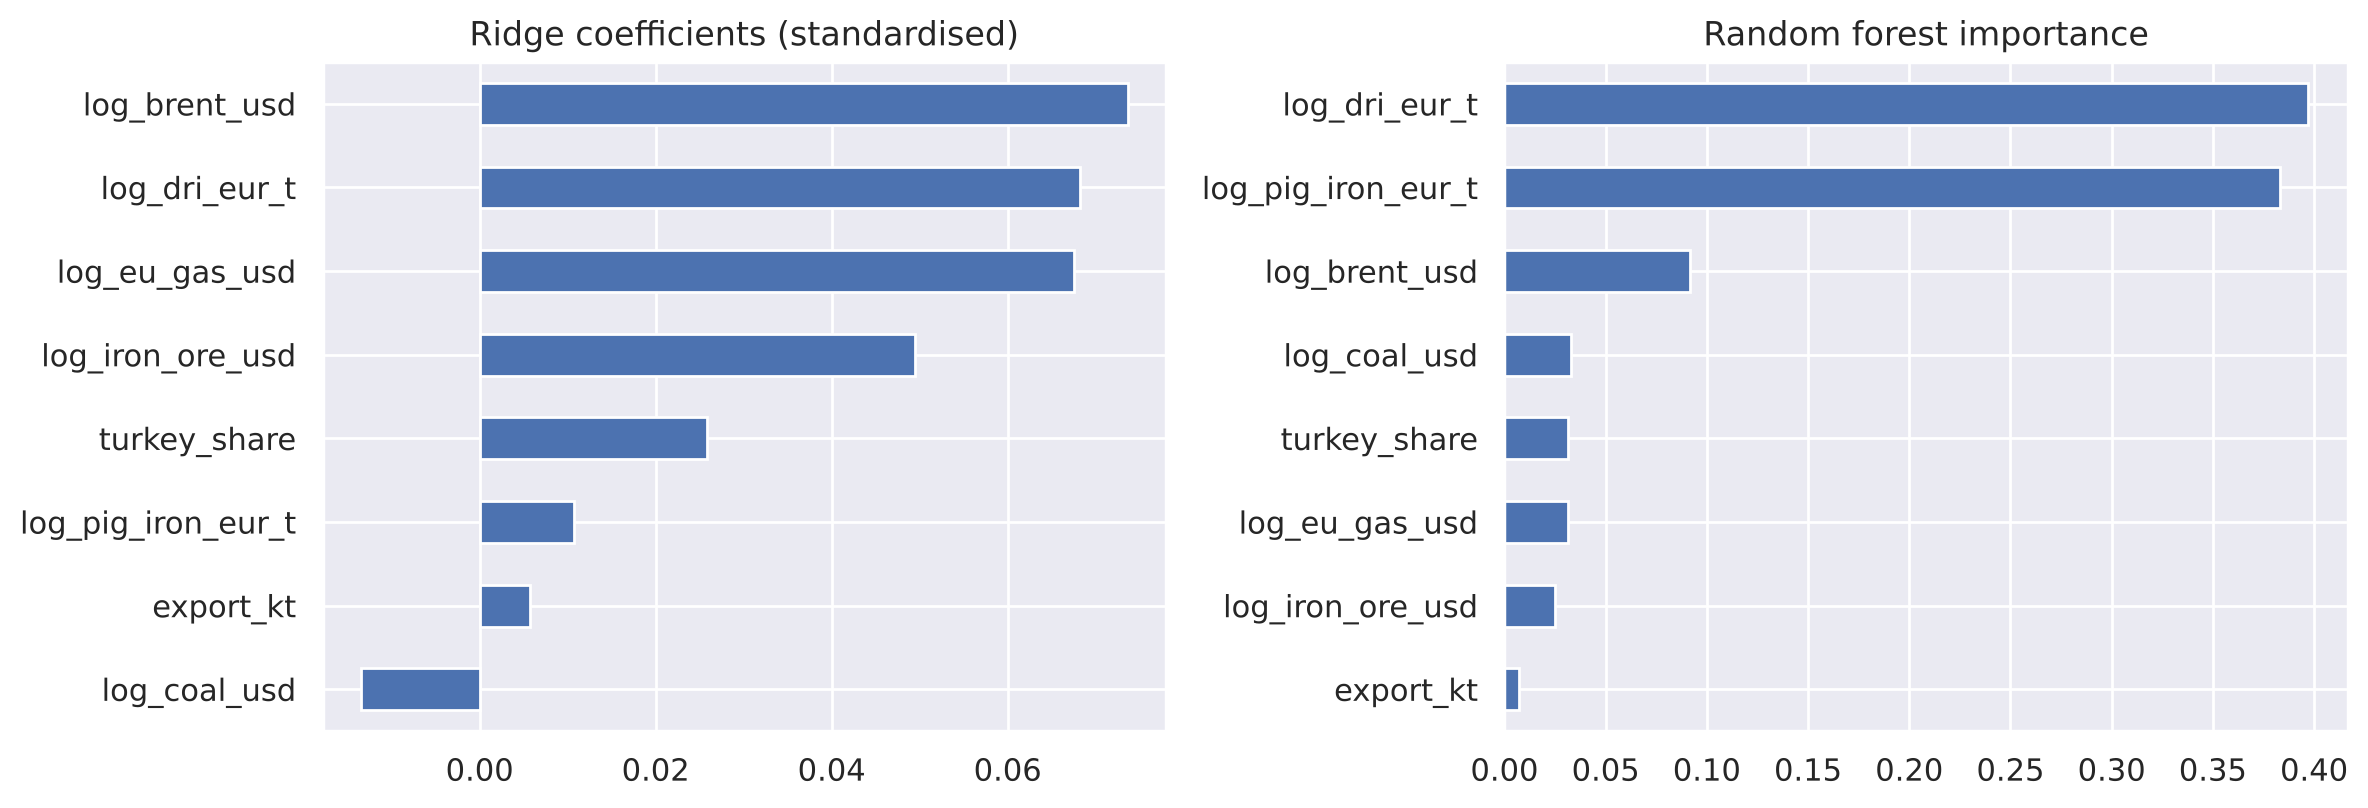

,ridge_coef,rf_importance
log_dri_eur_t,0.068178,0.396788
log_pig_iron_eur_t,0.010671,0.383061
log_brent_usd,0.073620,0.091780
log_coal_usd,-0.013492,0.032975
turkey_share,0.025823,0.031620
log_eu_gas_usd,0.067586,0.031596
log_iron_ore_usd,0.049447,0.024940
export_kt,0.005698,0.007242


In [9]:
drivers = DataFrame({
    'ridge_coef': best.named_steps['model'].coef_,
    'rf_importance': models['RandomForest'].feature_importances_}, index=X.columns).sort_values('rf_importance', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
drivers['ridge_coef'].sort_values().plot.barh(ax=axes[0], title='Ridge coefficients (standardised)')
drivers['rf_importance'].sort_values().plot.barh(ax=axes[1], title='Random forest importance')
plt.tight_layout()
plt.savefig('../outputs/figures/10_price_drivers.png')
plt.show()
drivers

## +10% in a driver
log-log regression on all months (correlation, not causation)

In [10]:
cols = ['log_pig_iron_eur_t', 'log_iron_ore_usd', 'log_coal_usd', 'log_eu_gas_usd']
lr = LinearRegression().fit(X[cols], y)
latest = df['scrap_eur_t'].iloc[-3:].mean()

whatif = DataFrame({'elasticity': lr.coef_}, index=['Pig iron', 'Iron ore', 'Coal', 'EU gas'])
whatif['scrap_change_eur_t_if_+10%'] = whatif['elasticity'] * 0.10 * latest
print('R2: {:.2f}, latest scrap price: {:.0f} EUR/t'.format(lr.score(X[cols], y), latest))
whatif

R2: 0.87, latest scrap price: 357 EUR/t


,elasticity,scrap_change_eur_t_if_+10%
Pig iron,0.292179,10.436167
Iron ore,0.222745,7.956094
Coal,0.029005,1.036007
EU gas,0.102434,3.658798


In [11]:
out = df.copy()
out['model_fit_eur_t'] = fit
out.reset_index().rename(columns={'index': 'date'}).to_csv('../data/processed/price_drivers_monthly.csv', index=False)
scores.to_csv('../data/processed/price_model_scores.csv')